# Task 6: does the app predict what the Task 5 models predict?

The brief asks to *confirm the app's prediction matches what your model gives directly in a notebook*.
This notebook does that in three steps:

1. **Model vs Task 5.** The models the app loads (`models/forecaster.joblib`, written by `scripts/export_models.py`)
   are compared with the predictions Task 5 saved for its 21-day test set (`reference/task5_test_predictions.csv`).
2. **Direct PyTorch / statsmodels vs the app's code.** The networks are rebuilt in PyTorch from the saved weights and
   run with Task 5's own `recursive_forecast` loop; SARIMA is re-fitted from scratch with Task 5's settings.
3. **Web app vs model.** The Django app is called through its JSON endpoint and compared with a direct call.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from torch import nn

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from forecast.forecaster import Forecaster, MODELS

fc = Forecaster(ROOT / "models" / "forecaster.joblib", ROOT / "data" / "cairo_temperature_hourly.npz")
ref = pd.read_csv(ROOT / "reference" / "task5_test_predictions.csv", index_col=0, parse_dates=True)
origins = ref.index[::24]          # the 21 test midnights, 11-31 Dec 2025
b = fc.bundle
print("bundle created:", b["created"])
print("SARIMA", b["sarima"]["order"], b["sarima"]["seasonal_order"], "fitted on", b["sarima"]["fitted_on"])
print("history:", fc.history.index[0], "->", fc.history.index[-1], f"({len(fc.history):,} hours)")
print("forecast starts allowed:", fc.first_origin, "->", fc.last_origin)

bundle created: 2026-10-30T10:41:02
SARIMA (2, 1, 2) (1, 1, 1, 24) fitted on ['2025-10-16 00:00:00', '2025-12-10 23:00:00']
history: 2001-01-01 00:00:00 -> 2025-12-31 23:00:00 (219,144 hours)
forecast starts allowed: 2001-02-26 00:00:00 -> 2026-01-01 00:00:00


## 1. The app's models vs the predictions saved by Task 5

In [2]:
def day_ahead(model):
    return pd.concat([fc.forecast(o, model=model, horizon=24).mean for o in origins])

rows, app_day = [], {}
for model in ["SARIMA", "LSTM", "Simple RNN", "ARIMA", "Seasonal naive", "Persistence"]:
    app_day[model] = day_ahead(model)
    t5 = ref[f"day_ahead_{model}"]
    rows.append({"model": model,
                 "app MAE (°C)": (app_day[model] - ref.actual).abs().mean(),
                 "Task 5 MAE (°C)": (t5 - ref.actual).abs().mean(),
                 "max |app − Task 5| (°C)": (app_day[model] - t5).abs().max()})
pd.DataFrame(rows).set_index("model").round(4)

,app MAE (°C),Task 5 MAE (°C),max |app − Task 5| (°C)
model,,,
SARIMA,0.9674,0.9513,0.7926
LSTM,1.1247,1.1247,0.0005
Simple RNN,1.5500,1.5500,0.0005
ARIMA,2.6639,2.7243,0.2912
Seasonal naive,1.1443,1.1443,0.0000
Persistence,3.8266,3.8266,0.0000


**Reading the table.**

- **LSTM, Simple RNN, seasonal naive and persistence** give the same forecasts as Task 5. The networks were
  re-trained with the same data, seeds and code, and the app's NumPy forward pass reproduces PyTorch.
- **SARIMA and ARIMA** differ by design. In Task 5's walk-forward test the models were **re-estimated every day**
  on the 8 weeks before each midnight. The app keeps the parameters estimated once (on the 8 weeks before the test
  set) and runs the Kalman filter on the 8 weeks before the chosen start. Re-estimating takes several seconds per
  request, and loading one fitted model at start-up is what the brief asks for. The accuracy cost is shown in the MAE
  columns.

In [3]:
one = pd.Series([fc.forecast(t, "SARIMA", 1).mean.iloc[0] for t in ref.index], ref.index)
print("SARIMA one-step-ahead (next hour), 504 test hours")
print(f"  max |app − Task 5| = {(one - ref.one_step_SARIMA).abs().max():.4f} °C")
print(f"  MAE app {(one - ref.actual).abs().mean():.4f} °C | MAE Task 5 {(ref.one_step_SARIMA - ref.actual).abs().mean():.4f} °C")

SARIMA one-step-ahead (next hour), 504 test hours
  max |app − Task 5| = 0.0009 °C
  MAE app 0.2317 °C | MAE Task 5 0.2317 °C


For the next hour Task 5 also kept the SARIMA parameters fixed and filtered through the test hours, so this is a
like-for-like check: the app gives the **same one-step forecasts**. The tiny remainder comes from where the Kalman filter starts
(Task 5 ran it continuously from the start of the 8-week window; the app starts it 8 weeks before each forecast).

## 2. Direct calls: PyTorch networks and a fresh SARIMA fit

In [4]:
# Task 5 cell 64, unchanged
class SimpleRNNNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 32, batch_first=True, nonlinearity="tanh")
        self.out = nn.Linear(32, 1)
    def forward(self, x):
        h, _ = self.rnn(x)
        return self.out(h[:, -1]).squeeze(-1)

class LSTMNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm1 = nn.LSTM(1, 64, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        self.out = nn.Linear(32, 1)
    def forward(self, x):
        h, _ = self.lstm1(x)
        h, _ = self.lstm2(self.drop(h))
        return self.out(h[:, -1]).squeeze(-1)

net_cfg = b["networks"]
lo, hi = net_cfg["scaler_min"], net_cfg["scaler_max"]
scaled = ((fc.history - lo) / (hi - lo)).astype(np.float32)

def recursive_forecast(model, origins, horizon=24, n_steps=48):
    # Task 5 cell 67: start from the 48 hours before each origin, feed predictions back in
    pos = [scaled.index.get_loc(o) for o in origins]
    window = np.stack([scaled.to_numpy()[p - n_steps:p] for p in pos])
    out = []
    model.eval()
    with torch.no_grad():
        for _ in range(horizon):
            nxt = model(torch.from_numpy(window[..., None])).numpy()
            out.append(nxt)
            window = np.concatenate([window[:, 1:], nxt[:, None]], axis=1)
    return np.stack(out, axis=1).ravel() * (hi - lo) + lo

for name, cls in [("Simple RNN", SimpleRNNNet), ("LSTM", LSTMNet)]:
    net = cls()
    net.load_state_dict({k: torch.tensor(v, dtype=torch.float32) for k, v in net_cfg["weights"][name].items()})
    direct = recursive_forecast(net, origins)
    print(f"{name:10s} PyTorch vs app: max diff {np.abs(direct - app_day[name].to_numpy()).max():.2e} °C | "
          f"PyTorch vs Task 5 file: {np.abs(direct - ref[f'day_ahead_{name}'].to_numpy()).max():.2e} °C")

Simple RNN PyTorch vs app: max diff 3.75e-05 °C | PyTorch vs Task 5 file: 5.64e-04 °C
LSTM       PyTorch vs app: max diff 1.62e-05 °C | PyTorch vs Task 5 file: 5.26e-04 °C


In [5]:
# Fit SARIMA from scratch exactly as Task 5 did (cell 43) and forecast 24 h from the test start
test_start = pd.Timestamp(b["test_start"])
s_tr = fc.history.loc[:test_start - pd.Timedelta(hours=1)].iloc[-8 * 7 * 24:]
fresh = SARIMAX(s_tr, order=b["sarima"]["order"], seasonal_order=b["sarima"]["seasonal_order"],
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
direct = fresh.get_forecast(24)
app = fc.forecast(test_start, "SARIMA", 24)
print("parameters, max |fresh − bundle|:", np.abs(fresh.params.to_numpy() - b["sarima"]["params"]).max())
print("24-h forecast, max |fresh − app| :", np.abs(direct.predicted_mean.to_numpy() - app.mean.to_numpy()).max())
print("95 % interval, max |fresh − app| :", np.abs(direct.conf_int().to_numpy() - np.c_[app.lower, app.upper]).max())

parameters, max |fresh − bundle|: 0.0
24-h forecast, max |fresh − app| : 0.0
95 % interval, max |fresh − app| : 0.0


## 3. Through the web app

In [6]:
import django
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "weather_site.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"  # Jupyter runs an event loop
django.setup()
from django.conf import settings
from django.test import Client
settings.ALLOWED_HOSTS.append("testserver")

client = Client()
checks = []
for model in MODELS:
    for origin in [origins[0], origins[14], pd.Timestamp("2026-01-01 00:00")]:
        r = client.get("/api/forecast/", {"date": f"{origin:%Y-%m-%d}", "hour": origin.hour, "model": model, "horizon": 24})
        web = np.array([h["temperature"] for h in r.json()["forecast"]])
        direct = fc.forecast(origin, model, 24).mean.to_numpy()
        checks.append({"model": model, "start": origin, "HTTP": r.status_code, "max |web − direct| (°C)": np.abs(web - direct).max()})
checks = pd.DataFrame(checks)
print("largest difference over", len(checks), "requests:", checks["max |web − direct| (°C)"].max(), "°C (the JSON rounds to 0.001)")
checks.head(6)

largest difference over 18 requests: 0.0004938791284772037 °C (the JSON rounds to 0.001)


,model,start,HTTP,max |web − direct| (°C)
0,SARIMA,2025-12-11,200,0.000480
1,SARIMA,2025-12-25,200,0.000487
2,SARIMA,2026-01-01,200,0.000486
3,LSTM,2025-12-11,200,0.000492
4,LSTM,2025-12-25,200,0.000466
5,LSTM,2026-01-01,200,0.000485


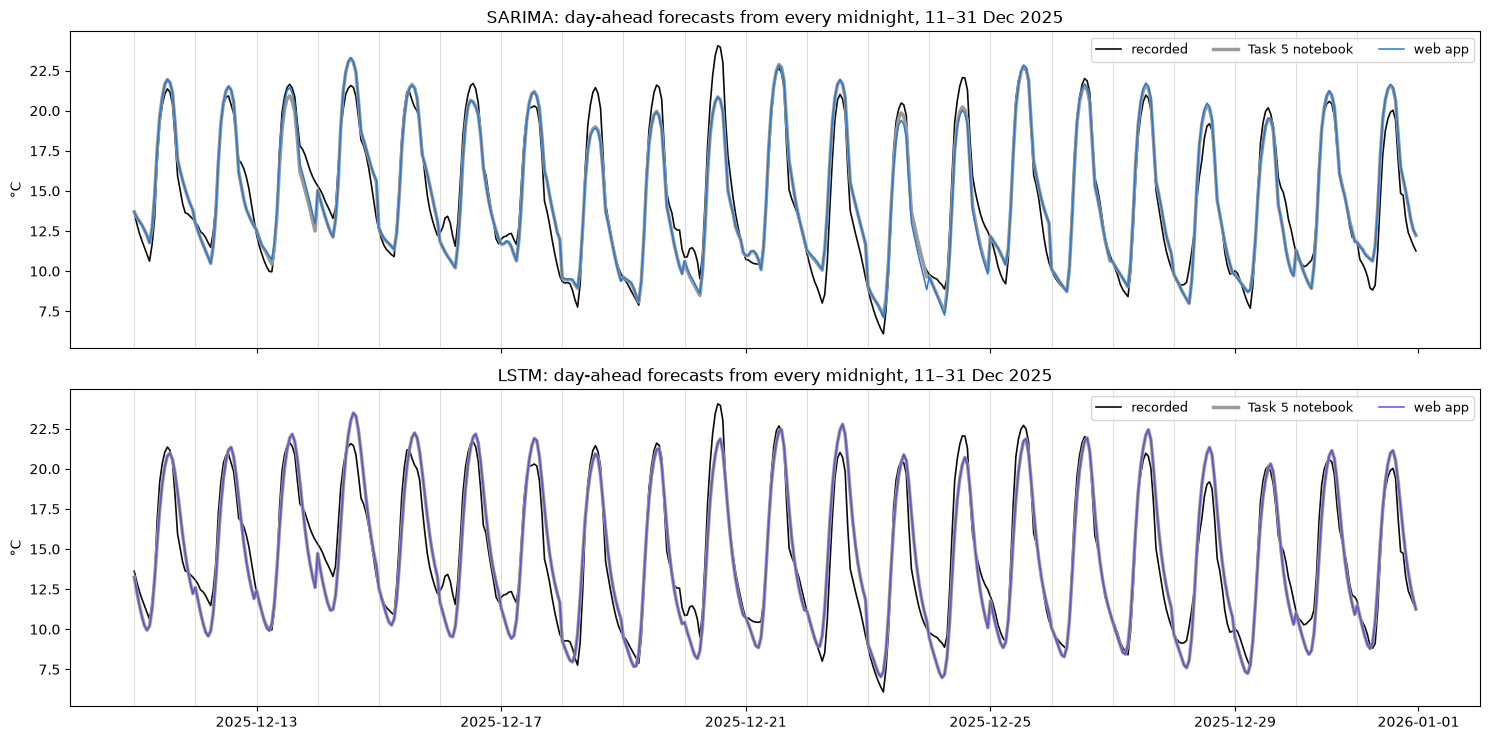

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True)
for ax, model, color in [(axes[0], "SARIMA", "#2a78d6"), (axes[1], "LSTM", "#6250d6")]:
    ax.plot(ref.actual, color="#0b0b0b", lw=1.2, label="recorded")
    ax.plot(ref[f"day_ahead_{model}"], color="#9a9a96", lw=2.5, label=f"Task 5 notebook")
    ax.plot(app_day[model], color=color, lw=1.1, label=f"web app")
    for d0 in origins:
        ax.axvline(d0, color="#9a9a96", lw=0.4, alpha=0.6)
    ax.set(title=f"{model}: day-ahead forecasts from every midnight, 11–31 Dec 2025", ylabel="°C")
    ax.legend(loc="upper right", ncol=3, fontsize=9)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/app_vs_task5.png", dpi=110, bbox_inches="tight")
plt.show()

## Conclusion

- The LSTM, Simple RNN and baselines in the app reproduce Task 5's saved test predictions, and the app's NumPy
  networks match PyTorch on the same weights.
- A fresh SARIMA fit with Task 5's settings gives the same parameters as the bundle, and the app's 24-hour forecast
  and 95 % interval from the test start equal the direct `get_forecast` call.
- The SARIMA one-step forecasts match Task 5. For day-ahead forecasts the app keeps one set of parameters instead
  of re-estimating daily, which costs a little accuracy (table in section 1).
- The JSON endpoint returns exactly what the model gives directly, for every model.